<a href="https://colab.research.google.com/github/MamataNarvekar99/mamata10-ML134/blob/main/KNN_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Nearest Neighbors (KNN) Classification



## Aim
**To implement and visualize the K-Nearest Neighbors (KNN) classification algorithm, compare different values of K, and observe the effect of using different numbers of features.**


**Author: Dr. Priya B. Pandharbale**


## Software Required
- Python
- NumPy
- Matplotlib
- Scikit-learn



##KNN Classification using the Iris Dataset

We use the Iris dataset. It contains flower measurements and three flower classes. To keep the visualization simple, we use two features: petal length and petal width.


In [1]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load Iris dataset
iris = load_iris()

# Use only two features for easy visualization
X = iris.data[:, 2:4]
y = iris.target

print("Dataset loaded successfully")
print("Number of samples:", len(X))
print("Features used:", iris.feature_names[2:4])


Dataset loaded successfully
Number of samples: 150
Features used: ['petal length (cm)', 'petal width (cm)']


In [2]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 120
Testing samples: 30


In [3]:
# Create and train the KNN model
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# Predict test data
y_pred = knn.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Predicted classes:", y_pred)
print("Actual classes:   ", y_test)
print("Accuracy:", round(accuracy * 100, 2), "%")


Predicted classes: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Actual classes:    [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Accuracy: 100.0 %


##  Visualize the Classification

The following graph shows the Iris test samples using petal length and petal width. Different colours represent different flower classes.


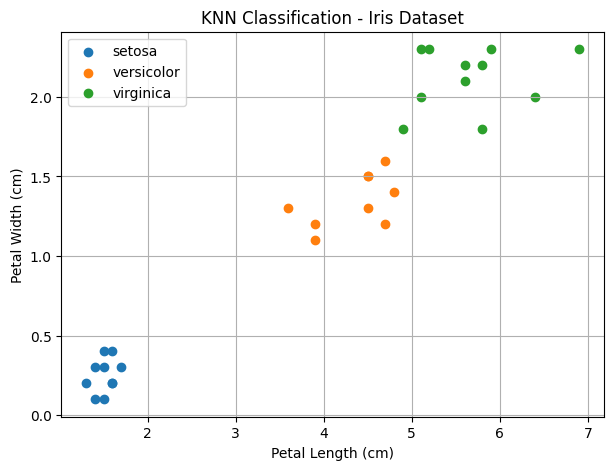

In [4]:
# Plot test samples
plt.figure(figsize=(7, 5))

for class_no in np.unique(y_test):
    plt.scatter(
        X_test[y_test == class_no, 0],
        X_test[y_test == class_no, 1],
        label=iris.target_names[class_no]
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("KNN Classification - Iris Dataset")
plt.legend()
plt.grid(True)
plt.show()


## Compare Different Values of K

K is the number of nearest neighbours considered for classification. We test K = 1, 3, 5, 7 and 9 and compare their accuracy.


In [5]:
# Compare different K values
k_values = [ 3, 5, 7, 9]
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    prediction = model.predict(X_test)
    score = accuracy_score(y_test, prediction)
    accuracies.append(score)

    print("K =", k, " Accuracy =", round(score * 100, 2), "%")


K = 3  Accuracy = 100.0 %
K = 5  Accuracy = 100.0 %
K = 7  Accuracy = 100.0 %
K = 9  Accuracy = 100.0 %


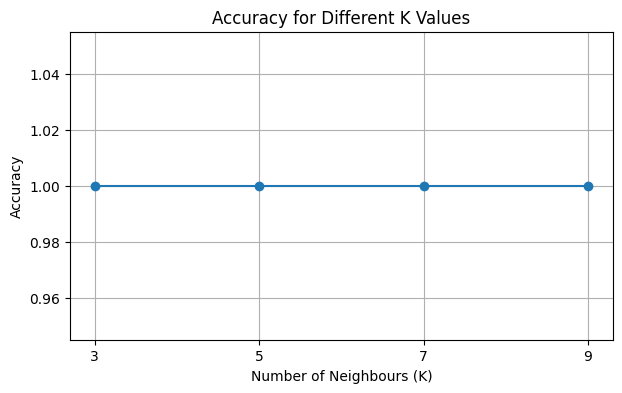

In [6]:
# Plot accuracy for different K values
plt.figure(figsize=(7, 4))
plt.plot(k_values, accuracies, marker="o")
plt.xlabel("Number of Neighbours (K)")
plt.ylabel("Accuracy")
plt.title("Accuracy for Different K Values")
plt.xticks(k_values)
plt.grid(True)
plt.show()


## Effect of Number of Features (Curse of Dimensionality)

We compare KNN using two features and all four features. KNN depends on distance calculations. When the number of features becomes very large, distances may become less useful for distinguishing samples. This is called the *curse of dimensionality*.

This small Iris example demonstrates the effect of adding features; it is an illustration, not proof that accuracy must decrease whenever features are added.


In [7]:
from sklearn.preprocessing import StandardScaler

# Use all four features
X_all = iris.data

X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X_all, y, test_size=0.2, random_state=42
)

# Standardize all four features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_all)
X_test_scaled = scaler.transform(X_test_all)

# Train KNN using all four features
knn_all = KNeighborsClassifier(n_neighbors=3)
knn_all.fit(X_train_scaled, y_train_all)

y_pred_all = knn_all.predict(X_test_scaled)
accuracy_all = accuracy_score(y_test_all, y_pred_all)

print("Accuracy using 2 features:", round(accuracy * 100, 2), "%")
print("Accuracy using 4 standardized features:", round(accuracy_all * 100, 2), "%")


Accuracy using 2 features: 100.0 %
Accuracy using 4 standardized features: 100.0 %


## Observations
1. KNN classifies a sample based on the classes of its nearest neighbours.
2. The value of K affects the classification accuracy.
3. A very small K can be sensitive to noise, while a larger K may smooth the decision.
4. Feature scaling is important because KNN uses distance calculations.
5. Adding more features can affect distance measurements. Very high-dimensional data may lead to the curse of dimensionality.

## Result
The K-Nearest Neighbors classifier was implemented successfully on the Iris dataset. The classification was visualized, different K values were compared, and the effect of using two and four features was observed.
